# LAB3 - Bài 3

## Câu a

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import KFold
from sklearn import metrics

import keras
from keras.datasets import mnist
from keras.models import Sequential
from keras.layers import Input, Flatten, Dense, Dropout

In [2]:
# Cố định seed để kết quả huấn luyện Neural Network có thể lặp lại
keras.utils.set_random_seed(42)

In [3]:
# Đọc bộ dữ liệu train, test của MNIST từ Keras
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

## Câu b

In [4]:
# Kích thước của tập train, test
print("Train images:", train_images.shape, "- Train labels:", train_labels.shape)
print("Test images:", test_images.shape, "- Test labels:", test_labels.shape)

Train images: (60000, 28, 28) - Train labels: (60000,)
Test images: (10000, 28, 28) - Test labels: (10000,)


Đặng Phan Duy - 6451071010

## Câu c

In [5]:
# Chuẩn hóa các giá trị pixel của ảnh về đoạn [0,1]
train_images = train_images / 255.0
test_images = test_images / 255.0

print("Train - Min:", train_images.min(), "- Max:", train_images.max())
print("Test - Min:", test_images.min(), "- Max:", test_images.max())

Train - Min: 0.0 - Max: 1.0
Test - Min: 0.0 - Max: 1.0


Đặng Phan Duy - 6451071010

## Câu d

In [6]:
# Hàm tạo và biên dịch Neural Network (tương tự câu 2)
def create_model():
    model = Sequential([
        Input(shape=(28, 28)),
        Flatten(),                          # làm phẳng ảnh 28x28 thành vector 784 chiều
        Dense(128, activation='relu'),      # 128 neuron, hàm kích hoạt Relu
        Dropout(0.2),                       # mỗi neuron có xác suất 20% bị tắt
        Dense(10, activation='softmax')     # 10 class (chữ số 0 - 9)
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

create_model().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Đặng Phan Duy - 6451071010

## Câu e

In [7]:
# Huấn luyện mô hình bằng k-fold cross validation (k = 10)
kfold = KFold(n_splits=10, shuffle=True, random_state=42)

models = []
accuracy_per_fold = []
loss_per_fold = []

fold_no = 1
for train_index, val_index in kfold.split(train_images):
    model = create_model()

    X_train_fold, X_val_fold = train_images[train_index], train_images[val_index]
    y_train_fold, y_val_fold = train_labels[train_index], train_labels[val_index]

    print('------------------------------------------------------------------------')
    print(f'Training for fold {fold_no} ...')
    model.fit(X_train_fold, y_train_fold, epochs=5, batch_size=32,
              validation_data=(X_val_fold, y_val_fold), verbose=1)

    # Lưu model huấn luyện được của fold
    models.append(model)

    # Tính accuracy và loss của fold trên tập validation
    loss, accuracy = model.evaluate(X_val_fold, y_val_fold, verbose=0)
    accuracy_per_fold.append(accuracy)
    loss_per_fold.append(loss)
    print(f'Score for fold {fold_no}: loss = {loss:.4f}; accuracy = {accuracy:.4f}')

    fold_no += 1

------------------------------------------------------------------------
Training for fold 1 ...
Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9089 - loss: 0.3096 - val_accuracy: 0.9587 - val_loss: 0.1468
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9556 - loss: 0.1506 - val_accuracy: 0.9692 - val_loss: 0.1057
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9666 - loss: 0.1120 - val_accuracy: 0.9757 - val_loss: 0.0847
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9713 - loss: 0.0914 - val_accuracy: 0.9757 - val_loss: 0.0807
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.9763 - loss: 0.0763 - val_accuracy: 0.9780 - val_loss: 0.0716
Score for fold 1: loss = 0.0716; accuracy = 0.9780
------------------------------------------------------------------------
Training for fold 2 ...
Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9096 - loss: 0.3120 - val_accuracy: 0.9495

Đặng Phan Duy - 6451071010

In [8]:
# Kết quả loss và accuracy của từng fold
fold_results = pd.DataFrame({
    'Fold': range(1, len(accuracy_per_fold) + 1),
    'Loss': loss_per_fold,
    'Accuracy': accuracy_per_fold
})
fold_results

,Fold,Loss,Accuracy
0,1,0.071557,0.978000
1,2,0.099705,0.971167
2,3,0.092176,0.972333
3,4,0.081740,0.975500
4,5,0.100374,0.970667
5,6,0.088056,0.975167
6,7,0.091910,0.972500
7,8,0.086088,0.974167
8,9,0.097962,0.970667
9,10,0.082211,0.974833


Đặng Phan Duy - 6451071010

## Câu f

In [9]:
# Mean, Standard deviation của Accuracy và Loss
print("Mean Accuracy:", np.mean(accuracy_per_fold))
print("Standard deviation Accuracy:", np.std(accuracy_per_fold))
print("Mean Loss:", np.mean(loss_per_fold))
print("Standard deviation Loss:", np.std(loss_per_fold))

Mean Accuracy: 0.973499995470047
Standard deviation Accuracy: 0.002304585449562011
Mean Loss: 0.08917791917920112
Standard deviation Loss: 0.008688776590445191


Đặng Phan Duy - 6451071010

## Câu g

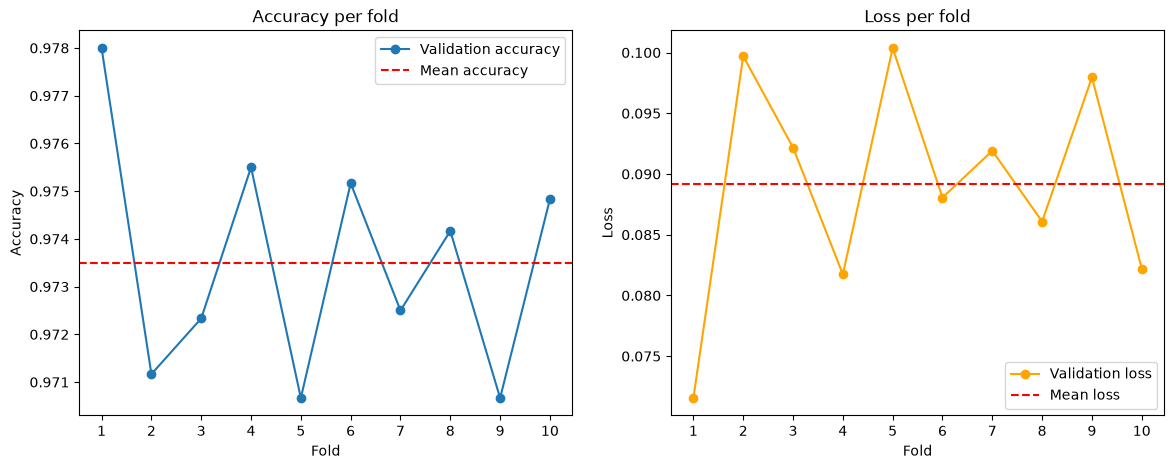

In [10]:
# Biểu đồ accuracy, loss sau mỗi fold
folds = range(1, len(accuracy_per_fold) + 1)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(folds, accuracy_per_fold, 'o-', label='Validation accuracy')
plt.axhline(np.mean(accuracy_per_fold), color='red', linestyle='--', label='Mean accuracy')
plt.title('Accuracy per fold')
plt.xlabel('Fold')
plt.ylabel('Accuracy')
plt.xticks(folds)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(folds, loss_per_fold, 'o-', color='orange', label='Validation loss')
plt.axhline(np.mean(loss_per_fold), color='red', linestyle='--', label='Mean loss')
plt.title('Loss per fold')
plt.xlabel('Fold')
plt.ylabel('Loss')
plt.xticks(folds)
plt.legend()
plt.show()

Đặng Phan Duy - 6451071010

## Câu h

In [11]:
# Chọn mô hình có Accuracy tốt nhất giữa các fold
best_index = np.argmax(accuracy_per_fold)
best_model = models[best_index]
print("Best fold:", best_index + 1, "- Accuracy:", accuracy_per_fold[best_index])

# Phân lớp cho tập test
test_prob = best_model.predict(test_images)
test_pred = np.argmax(test_prob, axis=1)
print("Predict:", test_pred[:20])
print("Actual: ", test_labels[:20])

Best fold: 1 - Accuracy: 0.9779999852180481
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Predict: [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]
Actual:  [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]


Đặng Phan Duy - 6451071010

## Câu i

In [12]:
# Accuracy của mô hình trên tập test
nn_score = metrics.accuracy_score(test_labels, test_pred)
print("Accuracy:", nn_score)

Accuracy: 0.9764


Đặng Phan Duy - 6451071010

## Câu j

In [13]:
# Precision, Recall, F1-score của từng lớp và trung bình
print("Report:\n", metrics.classification_report(test_labels, test_pred, digits=4))

Report:
               precision    recall  f1-score   support

           0     0.9720    0.9929    0.9823       980
           1     0.9860    0.9921    0.9890      1135
           2     0.9683    0.9767    0.9725      1032
           3     0.9760    0.9663    0.9711      1010
           4     0.9816    0.9766    0.9791       982
           5     0.9720    0.9742    0.9731       892
           6     0.9793    0.9854    0.9823       958
           7     0.9719    0.9747    0.9733      1028
           8     0.9821    0.9589    0.9704       974
           9     0.9740    0.9643    0.9691      1009

    accuracy                         0.9764     10000
   macro avg     0.9763    0.9762    0.9762     10000
weighted avg     0.9764    0.9764    0.9764     10000



Đặng Phan Duy - 6451071010

## Câu k

In [14]:
nn_cm = metrics.confusion_matrix(test_labels, test_pred)

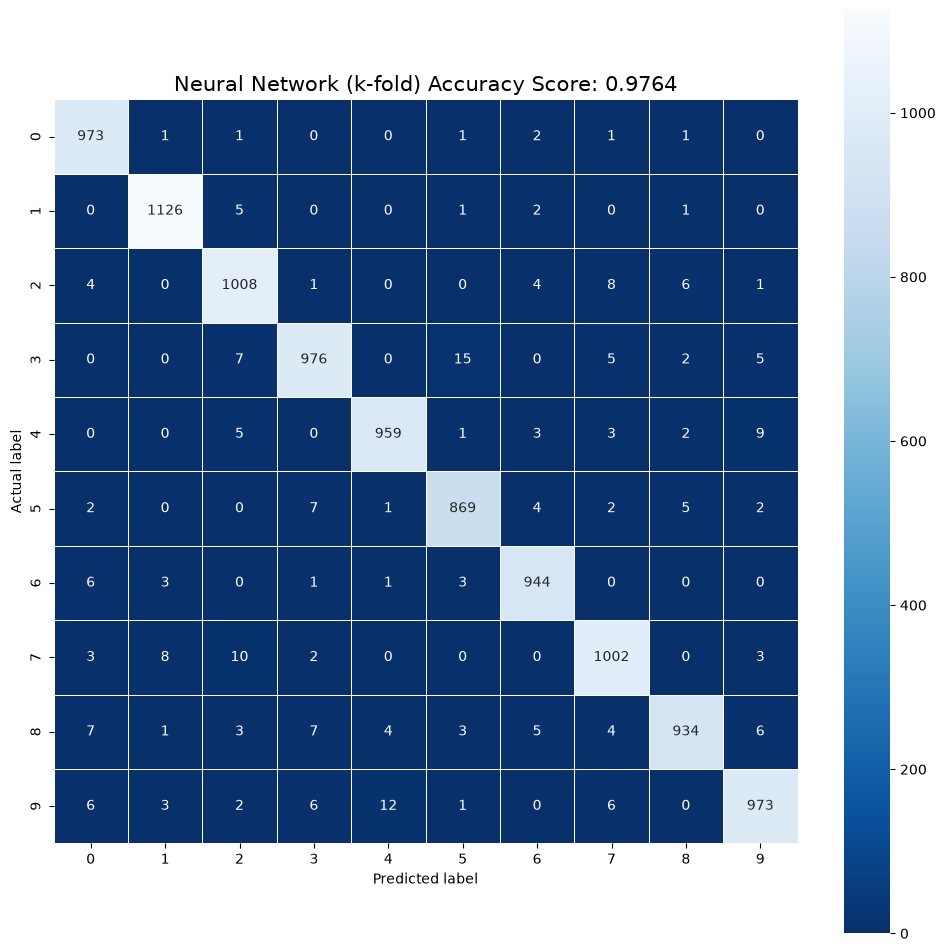

In [15]:
plt.figure(figsize=(12,12))
sns.heatmap(nn_cm, annot=True, fmt="d", linewidths=.5, square = True, cmap = 'Blues_r');
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'Neural Network (k-fold) Accuracy Score: {0}'.format(nn_score)
plt.title(title, size = 15);

Đặng Phan Duy - 6451071010

## Câu l

Ảnh 0: Predict = 7 - Actual = 7
Ảnh 1: Predict = 2 - Actual = 2
Ảnh 2: Predict = 1 - Actual = 1
Ảnh 3: Predict = 0 - Actual = 0
Ảnh 4: Predict = 4 - Actual = 4


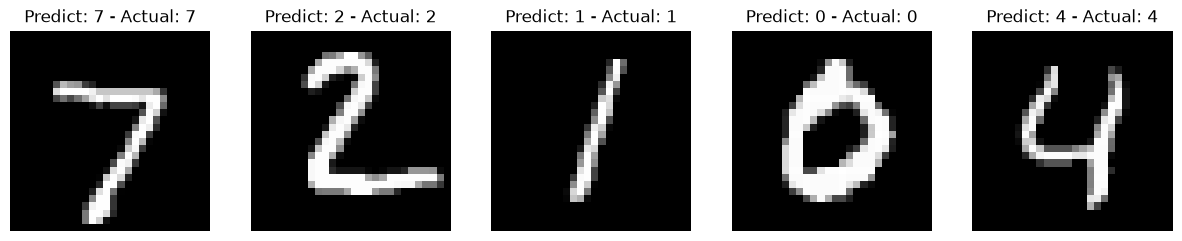

In [16]:
# Kết quả phân lớp của 05 ảnh đầu tiên trong tập test
plt.figure(figsize=(15, 4))
for image_index in range(5):
    img = np.expand_dims(test_images[image_index], axis=0)   # (1, 28, 28)
    pred = np.argmax(best_model.predict(img, verbose=0), axis=1)[0]
    print("Ảnh {0}: Predict = {1} - Actual = {2}".format(image_index, pred, test_labels[image_index]))

    plt.subplot(1, 5, image_index + 1)
    plt.imshow(test_images[image_index], cmap='gray')
    plt.title('Predict: {0} - Actual: {1}'.format(pred, test_labels[image_index]))
    plt.axis('off')
plt.show()

Đặng Phan Duy - 6451071010